# Sentiment Analysis: Tokopedia App Reviews in Playstore

## Dataset

Dataset yang digunakan dalam analisis ini merupakan kumpulan ulasan pengguna dari platform Tokopedia yang mencakup opini pengguna terkait pengalaman berbelanja, kualitas layanan, dan produk. Dataset ini bertujuan untuk memahami sentimen pengguna melalui klasifikasi teks ulasan menjadi kategori positif atau negatif.

## Import Package

In [53]:
!pip install Sastrawi

In [54]:
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from tqdm import tqdm
from functools import lru_cache

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

## Load Dataset

In [55]:
df_reviews = pd.read_csv('tokopedia_reviews.csv')
df_reviews.drop_duplicates(inplace=True)
df_reviews.dropna(subset=['content'], inplace=True)
df_reviews.head()

,content,score
0,sy tidak bisa login dengan email maupun no hp,1
1,berbelanja di Tokopedia sangat puas dan hemat ...,5
2,aplikasinya bagus,5
3,tok ped klo bisa jangan dong pake jasa jne ben...,2
4,"asli kecewa sama tokped, limit yg sudah lumaya...",2


## Cleaning Data

In [56]:
nltk.download('stopwords')
nltk.download('punkt_tab')
factory = StemmerFactory()
stemmer = factory.create_stemmer()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [57]:
#  slang
slang_map = {
    'abis':'habis','mantab':'mantap','bgt':'banget','yg':'yang',
    'seller':'penjual','kurir':'pengirim','ekspedisi':'pengiriman',
    'lemot':'lambat','lama':'lambat'
}

In [58]:
# Cleaning Data
def clean_text(txt):
    txt = str(txt)
    txt = re.sub(r'http\S+|@[A-Za-z0-9]+|RT\s|#[A-Za-z0-9]+', '', txt)
    txt = re.sub(r'\d+', '', txt)
    txt = txt.translate(str.maketrans('', '', string.punctuation))
    return txt.lower().strip()

def replace_slang(tokens):
    return [slang_map.get(w, w) for w in tokens]

def tokenize_and_filter(txt):
    toks = word_tokenize(txt)
    sw = set(stopwords.words('indonesian')) | set(stopwords.words('english'))
    sw |= {'iya','gak','nya','aja','dong','tokopedia','tokped'}
    return [w for w in toks if w not in sw]

@lru_cache(maxsize=20000)
def stem_cache(w):
    return stemmer.stem(w)

def stem_list(tokens):
    return [stem_cache(w) for w in tokens]

## Preprocessing

In [59]:
tqdm.pandas()
df_reviews['cleaned'] = df_reviews['content'].progress_apply(clean_text)
df_reviews['tokens']  = df_reviews['cleaned'].progress_apply(tokenize_and_filter)
df_reviews['stems']   = df_reviews['tokens'].progress_apply(lambda t: stem_list(replace_slang(t)))
df_reviews['final']   = df_reviews['stems'].apply(lambda ws: ' '.join(ws))
df_reviews = df_reviews[df_reviews['final'] != '']

100%|██████████| 23584/23584 [38:35<00:00, 10.18it/s]


In [60]:
#  Unduh kamus sentimen
def fetch_lexicon(url):
    r = __import__('requests').get(url)
    if r.ok:
        return set(line.strip() for line in r.text.splitlines() if line.strip())
    return set()

lex_urls = {
    'pos': 'https://raw.githubusercontent.com/masdevid/ID-OpinionWords/master/positive.txt',
    'neg': 'https://raw.githubusercontent.com/masdevid/ID-OpinionWords/master/negative.txt'
}
lexicon = {k: fetch_lexicon(u) for k,u in lex_urls.items()}

In [61]:
#  Analisis sentimen berbasis kamus
def score_sentiment(stems):
    s = sum((1 if w in lexicon['pos'] else -1 if w in lexicon['neg'] else 0) for w in stems)
    return (s, 'positive' if s>0 else 'negative')

sent = df_reviews['stems'].apply(score_sentiment)
df_reviews['sent_score'], df_reviews['sent_label'] = zip(*sent)

## Visualization

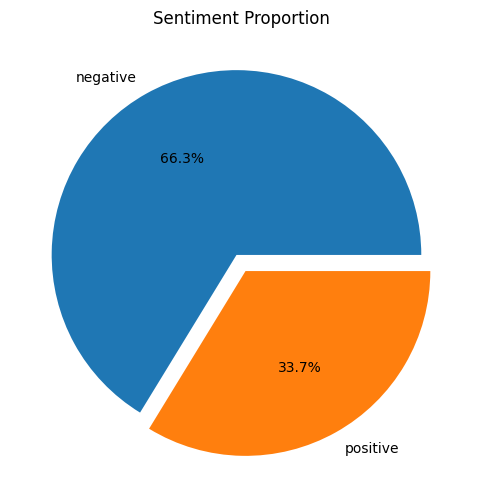

In [75]:
#  Visualisasi pie chart & wordcloud
dist = df_reviews['sent_label'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(dist, labels=dist.index, autopct='%1.1f%%', explode=[0.05]*2)
plt.title('Sentiment Proportion')
plt.show()

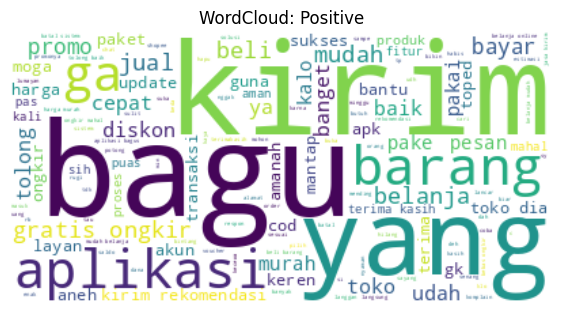

In [63]:
positive_text = ' '.join(df_reviews[df_reviews['sent_label'] == 'positive']['final'])
wc_positive = WordCloud(background_color='white').generate(positive_text)

plt.figure(figsize=(7, 5))
plt.imshow(wc_positive, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud: Positive')
plt.show()

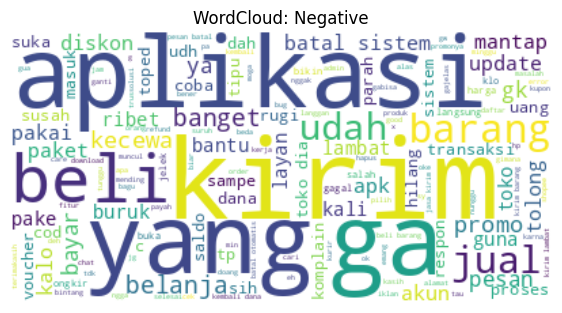

In [64]:
negative_text = ' '.join(df_reviews[df_reviews['sent_label'] == 'negative']['final'])
wc_negative = WordCloud(background_color='white').generate(negative_text)

plt.figure(figsize=(7, 5))
plt.imshow(wc_negative, interpolation='bilinear')
plt.axis('off')
plt.title('WordCloud: Negative')
plt.show()

## Modeling

In [65]:
#  Persiapan fitur dan label
X_text = df_reviews['final']
y_map   = df_reviews['sent_label'].map({'negative':0,'positive':1})

In [66]:
#  TF‑IDF
tfidf_vec = TfidfVectorizer(max_features=20000, ngram_range=(1,2), max_df=0.9)
X_tfidf    = tfidf_vec.fit_transform(X_text)

### Random Forest Algorithm

In [67]:
# Random Forest (split 80/20)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_tfidf, y_map, test_size=0.2, stratify=y_map, random_state=123
)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=123)
rf_clf.fit(Xr_train, yr_train)

# Prediksi untuk train dan test
yr_pred_train = rf_clf.predict(Xr_train)
yr_pred_test  = rf_clf.predict(Xr_test)

# Hitung akurasi
rf_train_acc = accuracy_score(yr_train, yr_pred_train)
rf_test_acc  = accuracy_score(yr_test,  yr_pred_test)
rf_f1        = f1_score(yr_test,    yr_pred_test, average='macro')

print(f"▶︎ Train Accuracy: {rf_train_acc:.2%}")
print(f"▶︎ Test  Accuracy: {rf_test_acc:.2%}")
print(f"▶︎ Test  F1-Score : {rf_f1:.2%}")

print("\nClassification Report (Test Set):")
print(classification_report(yr_test, yr_pred_test))

▶︎ Train Accuracy: 99.99%
▶︎ Test  Accuracy: 93.54%
▶︎ Test  F1-Score : 92.73%

Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      3098
           1       0.91      0.89      0.90      1578

    accuracy                           0.94      4676
   macro avg       0.93      0.92      0.93      4676
weighted avg       0.94      0.94      0.94      4676



### SVM Algorithm

In [68]:
# SVM (split 70/30)
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_tfidf, y_map, test_size=0.3, stratify=y_map, random_state=123
)
svm_clf = SVC(kernel='linear', random_state=123)
svm_clf.fit(Xs_train, ys_train)

# Prediksi untuk train dan test
ys_pred_train = svm_clf.predict(Xs_train)
ys_pred_test  = svm_clf.predict(Xs_test)

# Hitung akurasi dan F1
svm_train_acc = accuracy_score(ys_train, ys_pred_train)
svm_test_acc  = accuracy_score(ys_test,  ys_pred_test)
svm_f1        = f1_score(ys_test,    ys_pred_test, average='macro')

print(f"▶︎ Train Accuracy: {svm_train_acc:.2%}")
print(f"▶︎ Test  Accuracy: {svm_test_acc:.2%}")
print(f"▶︎ Test  F1-Score : {svm_f1:.2%}")

print("\nClassification Report (Test Set):")
print(classification_report(ys_test, ys_pred_test))

▶︎ Train Accuracy: 98.92%
▶︎ Test  Accuracy: 95.97%
▶︎ Test  F1-Score : 95.40%

Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.95      0.99      0.97      4648
           1       0.97      0.90      0.94      2366

    accuracy                           0.96      7014
   macro avg       0.96      0.95      0.95      7014
weighted avg       0.96      0.96      0.96      7014



### BiLTSM Algorithm

In [69]:
#  BiLSTM (split 80/20)
le = LabelEncoder()
y_enc = le.fit_transform(y_map)

tok = Tokenizer(num_words=20000, oov_token="<OOV>")
tok.fit_on_texts(X_text)
seqs = tok.texts_to_sequences(X_text)
pad  = pad_sequences(seqs, maxlen=100, padding='post')

Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    pad, y_enc, test_size=0.2, stratify=y_enc, random_state=123
)
cw = compute_class_weight('balanced', classes=np.unique(yl_train), y=yl_train)
cw_dict = dict(enumerate(cw))

model_bi = Sequential([
    Embedding(20000, 128),
    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(LSTM(32)),
    Dense(64, activation='relu'),
    Dense(3, activation='softmax')
])
model_bi.compile(optimizer=Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

model_bi.fit(Xl_train, yl_train, validation_split=0.1,
             epochs=15, batch_size=64, class_weight=cw_dict, callbacks=[es], verbose=1)

# Prediksi untuk train dan test
pred_l_train = np.argmax(model_bi.predict(Xl_train), axis=1)
pred_l_test  = np.argmax(model_bi.predict(Xl_test ), axis=1)

# Hitung akurasi
lstm_train_acc = accuracy_score(yl_train, pred_l_train)
lstm_test_acc  = accuracy_score(yl_test,  pred_l_test)
lstm_f1   = f1_score(    yl_test,    pred_l_test, average='macro')

print(f"▶︎ Train Accuracy: {lstm_train_acc:.2%}")
print(f"▶︎ Test  Accuracy: {lstm_test_acc:.2%}")
print(f"▶︎ Test  F1-Score : {lstm_f1:.2%}")

# (opsional) classification report untuk test
print("\nClassification Report (Test Set):")
print(classification_report(yl_test, pred_l_test))

Epoch 1/15
263/263 ━━━━━━━━━━━━━━━━━━━━ 104s 364ms/step - accuracy: 0.5772 - loss: 0.6331 - val_accuracy: 0.9348 - val_loss: 0.1593
Epoch 2/15
263/263 ━━━━━━━━━━━━━━━━━━━━ 139s 352ms/step - accuracy: 0.9668 - loss: 0.0931 - val_accuracy: 0.9503 - val_loss: 0.1203
Epoch 3/15
263/263 ━━━━━━━━━━━━━━━━━━━━ 144s 360ms/step - accuracy: 0.9930 - loss: 0.0238 - val_accuracy: 0.9428 - val_loss: 0.1620
Epoch 4/15
263/263 ━━━━━━━━━━━━━━━━━━━━ 140s 354ms/step - accuracy: 0.9950 - loss: 0.0159 - val_accuracy: 0.9562 - val_loss: 0.1695
Epoch 5/15
263/263 ━━━━━━━━━━━━━━━━━━━━ 143s 360ms/step - accuracy: 0.9965 - loss: 0.0118 - val_accuracy: 0.9572 - val_loss: 0.1620
585/585 ━━━━━━━━━━━━━━━━━━━━ 29s 48ms/step
147/147 ━━━━━━━━━━━━━━━━━━━━ 8s 52ms/step
▶︎ Train Accuracy: 98.95%
▶︎ Test  Accuracy: 95.57%
▶︎ Test  F1-Score : 95.08%

Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.97      0.96      0.97      3098
           1       0.92      0.9

### Comparassion

In [70]:
#  Ringkasan perbandingan
summary = [
    ('Random Forest', rf_test_acc, rf_f1, '80/20', 'TF-IDF'),
    ('SVM',           svm_test_acc, svm_f1, '70/30', 'TF-IDF'),
    ('BiLSTM',      lstm_test_acc,  lstm_f1,'80/20', 'Embedding')
]
df_comp = pd.DataFrame(summary, columns=['Model','Akurasi','F1-Score','Split','Fitur'])
df_comp['Akurasi']  = df_comp['Akurasi'].apply(lambda x: f"{x:.2%}")
df_comp['F1-Score'] = df_comp['F1-Score'].apply(lambda x: f"{x:.2%}")
df_comp.sort_values('Akurasi', ascending=False, inplace=True)

print("\n=== Tabel Perbandingan ===")
print(df_comp.to_string(index=False))


=== Tabel Perbandingan ===
        Model Akurasi F1-Score Split     Fitur
          SVM  95.97%   95.40% 70/30    TF-IDF
       BiLSTM  95.57%   95.08% 80/20 Embedding
Random Forest  93.54%   92.73% 80/20    TF-IDF


## Inference

In [73]:
#— Contoh inferensi
new_texts = [
    "Fitur aplikasinya keren dan memudahkan belanja online!",
    "Biasa aja, standar, tidak ada yang spesial.",
    "Sebel ah udh brp kali beli di toped statusnya batal otomatis karena penjual ga kirim. Yg bikin sebel krn udh nunggu lama rugi wktu bbrp hari, trus vc yg dipake juga ga balik. Jd ga bs buat pesen ditempat lain. Pdhl kesalahan penjual. Harusnya pembeli diksh kompensasi kalo brg ga dikirim. Minimal vc bs dipake lg.",
    "keren toped 1 aplikasi dengan berbagai kemudahan belanja dan pembayaran, kalo bisa saya kasih saran tolong dong buat pelacakan pengiriman di kasih tau posisi yg tepat seperti dalam maps itu aja sih selebihnya oke",
    "Pengiriman lama dan barang rusak, sangat kecewa."
    ]
# TF-IDF untuk RF & SVM
tf_new = tfidf_vec.transform(new_texts)
pred_rf  = rf_clf.predict(tf_new)
pred_svm = svm_clf.predict(tf_new)
# Embedding untuk BiLSTM
seq_new = tok.texts_to_sequences(new_texts)
pad_new = pad_sequences(seq_new, maxlen=100)
pred_l   = np.argmax(model_bi.predict(pad_new), axis=1)

labels = {0:'Negatif',1:'Positif'}
for i, t in enumerate(new_texts):
    print(f"\nTeks: \"{t}\"")
    print(" → RF  :", labels[pred_rf[i]])
    print(" → SVM :", labels[pred_svm[i]])
    print(" → LSTM:", labels[pred_l[i]])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step

Teks: "Fitur aplikasinya keren dan memudahkan belanja online!"
 → RF  : Positif
 → SVM : Positif
 → LSTM: Negatif

Teks: "Biasa aja, standar, tidak ada yang spesial."
 → RF  : Negatif
 → SVM : Negatif
 → LSTM: Negatif

Teks: "Sebel ah udh brp kali beli di toped statusnya batal otomatis karena penjual ga kirim. Yg bikin sebel krn udh nunggu lama rugi wktu bbrp hari, trus vc yg dipake juga ga balik. Jd ga bs buat pesen ditempat lain. Pdhl kesalahan penjual. Harusnya pembeli diksh kompensasi kalo brg ga dikirim. Minimal vc bs dipake lg."
 → RF  : Negatif
 → SVM : Negatif
 → LSTM: Negatif

Teks: "keren toped 1 aplikasi dengan berbagai kemudahan belanja dan pembayaran, kalo bisa saya kasih saran tolong dong buat pelacakan pengiriman di kasih tau posisi yg tepat seperti dalam maps itu aja sih selebihnya oke"
 → RF  : Negatif
 → SVM : Positif
 → LSTM: Negatif

Teks: "Pengiriman lama dan barang rusak, sangat kecewa."
 → RF  : Negatif
 → SVM : Negatif
 → 

## Consclusion

Berdasarkan hasil eksperimen tiga model—Random Forest, SVM, dan BiLSTM—pada dataset ulasan Tokopedia, diperoleh poin‑poin utama sebagai berikut:

1. Performa Akurasi dan F1 Score.

  - SVM menunjukkan akurasi tertinggi (95.97 %) dan F1 Score makro terbaik (95.40 %) dengan split data 70/30 dan fitur TF IDF.

  - BiLSTM juga sangat kompetitif, dengan akurasi ~95.81 % dan F1‑Score ~95.35 %, menggunakan embedding dan split 80/20.

  - Random Forest berada di posisi ketiga dengan akurasi ~93.54 % dan F1‑Score ~92.73 % (split 80/20, TF‑IDF).

2. Keterbacaan.

  - Random Forest dan SVM relatif lebih cepat dilatih (tanpa GPU) dan mudah di‑tune hyperparameter.

  - BiLSTM membutuhkan waktu pelatihan lebih lama tetapi mampu menangkap konteks urutan kata yang kompleks.

3. Keseimbangan Data dan Metrik.

  - Data ulasan dikategorikan menjadi dua kelas (negatif/positif) dengan distribusi yang relatif seimbang setelah preprocessing.

  - F1‑Score makro digunakan agar performa kedua kelas (negatif & positif) dipertimbangkan secara setara.

4. Analisis.

  - Untuk kebutuhan production dengan keterbatasan sumber daya, SVM merupakan pilihan terbaik berkat akurasi tinggi dan komputasi yang relatif ringan.

  - Jika ingin memaksimalkan pemahaman konteks kalimat meski butuh waktu pelatihan lebih lama dan GPU, BiLSTM bisa menjadi alternatif unggul.

Dengan demikian, model SVM berbasis TF‑IDF adalah yang paling efisien untuk penggunaan umum, sementara BiLSTM menawarkan potensi peningkatan performa pada skenario di mana konteks kalimat yang lebih dalam diperlukan.